# Q-Rescue

## Calibrated Risk-Aware Quantum Optimization for Emergency Routing

This is the first small teaching prototype. It connects a synthetic four-route decision to a manually constructed QUBO, verifies the exact answer by exhaustive search, and then runs reproducible PennyLane QAOA experiments. It makes no claim of quantum advantage or publication novelty.

## 1. Research motivation

An expected-time-only dispatcher can prefer a route whose arrival time is less predictable. Q-Rescue asks whether uncertainty can be included explicitly in a route objective and then encoded transparently for quantum optimization research.

The teaching question is deliberately narrow: **can one ambulance select exactly one of four routes while minimizing an understandable risk-aware score?** Exhaustive classical search remains the correctness reference.

## 2. Prototype scope

This milestone uses one ambulance, one hospital, four pre-enumerated routes, static synthetic inputs, four qubits, a noiseless simulator, and QAOA depths 1 and 2. It does not include traffic prediction, calibrated intervals, dynamic rerouting, multiple vehicles, real maps, noise, or hardware.

Reproducibility settings are visible below. The notebook imports every implementation from `src/`; the algorithm is not copied into notebook cells.

In [49]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").exists():
    raise FileNotFoundError("Run this notebook from QRescue or QRescue/notebooks.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

import matplotlib
import networkx as nx
import numpy as np
import pandas as pd
import pennylane as qml
from IPython.display import display
from pennylane import numpy as pnp

from src.classical_solver import generate_binary_assignments, solve_qubo
from src.quantum_qaoa import (
    create_mixer_hamiltonian,
    create_sampling_qnode,
    create_training_qnode,
    optimize_qaoa,
    summarize_samples,
)
from src.qubo import build_qubo, evaluate_qubo, qubo_to_ising
from src.risk_model import (
    add_risk_scores,
    choose_expected_time_route,
    choose_risk_aware_route,
)
from src.route_data import (
    calculate_path_time,
    create_road_network,
    create_route_dataframe,
    get_candidate_paths,
)
from src.visualization import (
    save_measurement_probabilities_figure,
    save_qaoa_circuit_figure,
    save_qubo_matrix_figure,
    save_road_network_figure,
    save_route_comparison_figure,
    save_training_history_figure,
)

UNCERTAINTY_WEIGHT = 1.0
PENALTY = 50.0
DEPTHS = [1, 2]
TRAINING_ITERATIONS = 100
STEP_SIZE = 0.02
FINAL_SHOTS = 4000
RANDOM_SEED = 2026
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_rows", 20)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

environment = pd.DataFrame(
    {
        "component": ["Python", "PennyLane", "NumPy", "pandas", "NetworkX", "matplotlib"],
        "version": [
            sys.version.split()[0],
            qml.__version__,
            np.__version__,
            pd.__version__,
            nx.__version__,
            matplotlib.__version__,
        ],
    }
)
display(environment)
print("Supported QAOA cost layer:", callable(qml.qaoa.cost_layer))
print("Supported QAOA mixer layer:", callable(qml.qaoa.mixer_layer))

,component,version
0,Python,3.12.10
1,PennyLane,0.45.1
2,NumPy,2.4.4
3,pandas,2.3.3
4,NetworkX,3.6.1
5,matplotlib,3.11.1


Supported QAOA cost layer: True
Supported QAOA mixer layer: True


## 3. Route network

A directed graph stores locations as nodes and travel segments as arrows. Each edge below has a fixed `time_minutes` value. Every candidate route is a separate two-edge path from **Ambulance Station** through one junction to **Hospital**. The four panels highlight the routes separately so no path is hidden by another.

,route,path,calculated_time_minutes
0,Route A,Ambulance Station -> Junction A -> Hospital,18.000000
1,Route B,Ambulance Station -> Junction B -> Hospital,21.000000
2,Route C,Ambulance Station -> Junction C -> Hospital,24.000000
3,Route D,Ambulance Station -> Junction D -> Hospital,20.000000


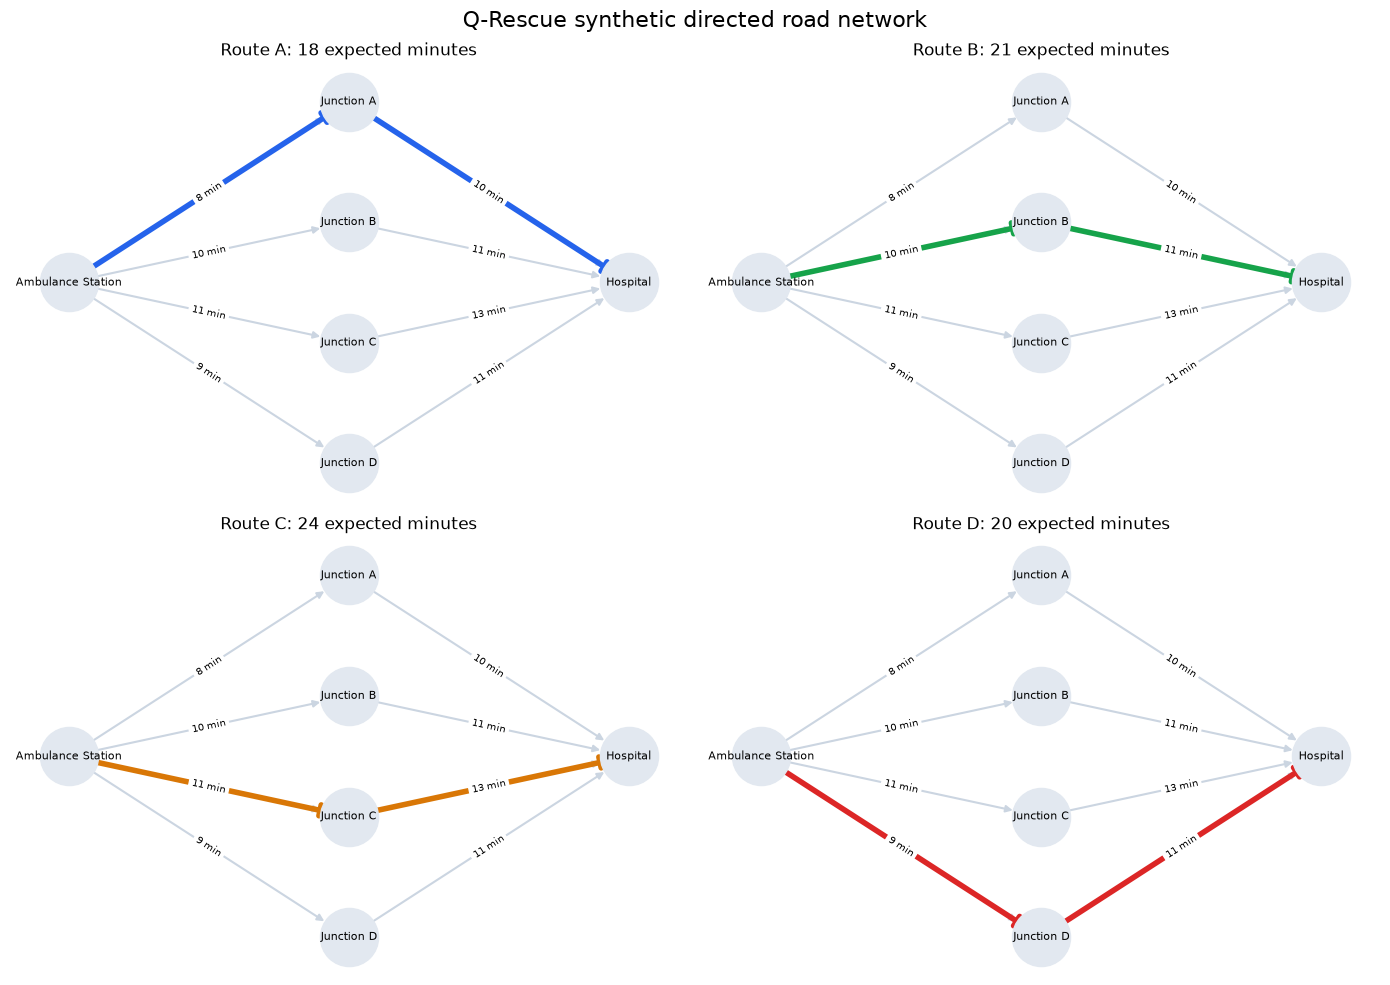

In [50]:
road_graph = create_road_network()
candidate_paths = get_candidate_paths()

path_time_rows = []
for route_name, path in candidate_paths.items():
    path_time_rows.append(
        {
            "route": route_name,
            "path": " -> ".join(path),
            "calculated_time_minutes": calculate_path_time(road_graph, path),
        }
    )
path_times = pd.DataFrame(path_time_rows)
display(path_times)

save_road_network_figure(
    road_graph,
    candidate_paths,
    RESULTS_DIR / "road_network.png",
)

## 4. Candidate-route data

The expected times are fixed synthetic values. The uncertainty values are also **manually simulated**: they are not fitted standard deviations and not calibrated machine-learning prediction intervals. A later milestone will replace them only after calibration has been measured.

In [51]:
route_data = create_route_dataframe()
display(route_data)

merged_time_check = route_data.merge(path_times[["route", "calculated_time_minutes"]], on="route")
assert np.allclose(
    merged_time_check["expected_time_minutes"],
    merged_time_check["calculated_time_minutes"],
)
print("Check passed: every graph path equals its stated expected time.")

,route,expected_time_minutes,uncertainty_minutes
0,Route A,18.000000,10.000000
1,Route B,21.000000,2.000000
2,Route C,24.000000,3.000000
3,Route D,20.000000,7.000000


Check passed: every graph path equals its stated expected time.


## 5. Expected-time baseline

The baseline chooses the index with minimum expected time:

$$i^*_{\mathrm{time}} = \arg\min_i t_i.$$

It ignores uncertainty. Since Route A has 18 expected minutes, this baseline should select Route A.

In [52]:
expected_time_choice = choose_expected_time_route(route_data)
print("Expected-time baseline:", expected_time_choice)
assert expected_time_choice == "Route A"


Expected-time baseline: Route A


## 6. Risk-aware score

Before calculating it, define the score for route $i$:

$$r_i = t_i + w u_i,$$

where $t_i$ is expected minutes, $u_i$ is manually simulated uncertainty minutes, and $w=1.0$ is the uncertainty weight. The values are therefore 28, 23, 27, and 27. This minute-equivalent teaching score expresses a preference; it is not a probability of harm or delay.

,route,expected_time_minutes,uncertainty_minutes,risk_score
0,Route A,18.000000,10.000000,28.000000
1,Route B,21.000000,2.000000,23.000000
2,Route C,24.000000,3.000000,27.000000
3,Route D,20.000000,7.000000,27.000000


Risk-aware choice: Route B


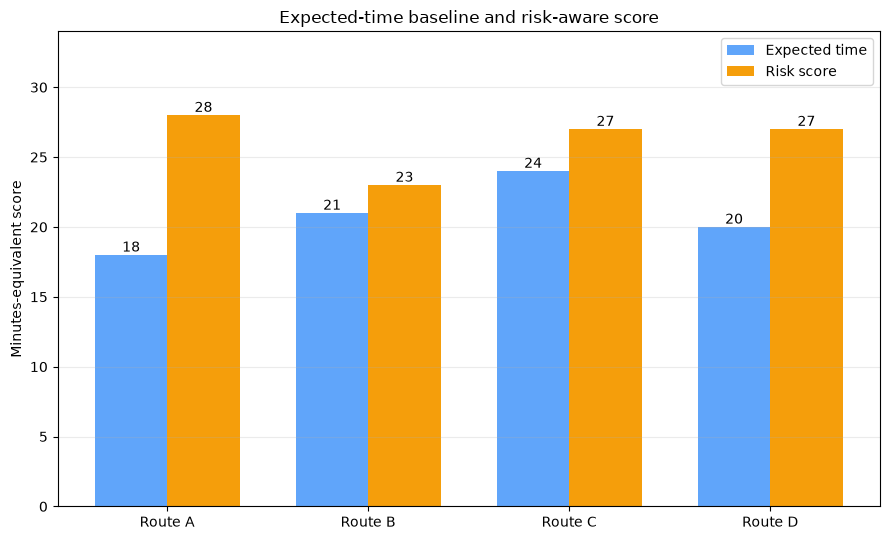

In [53]:
scored_routes = add_risk_scores(route_data, UNCERTAINTY_WEIGHT)
risk_aware_choice = choose_risk_aware_route(scored_routes)
display(scored_routes)
print("Risk-aware choice:", risk_aware_choice)
assert risk_aware_choice == "Route B"

save_route_comparison_figure(
    scored_routes,
    RESULTS_DIR / "route_comparison.png",
)

## 7. Binary decision variables

Use one binary variable per route:

$$x_0=A,\quad x_1=B,\quad x_2=C,\quad x_3=D.$$

Here `x_i = 1` means that route is selected and `x_i = 0` means it is not. The displayed bitstring order is always `x_0 x_1 x_2 x_3`; therefore `0100` means Route B. PennyLane wires 0, 1, 2, and 3 use this same order, with no silent reversal.

In [54]:
route_names = scored_routes["route"].tolist()
risk_scores = scored_routes["risk_score"].tolist()
variable_map = pd.DataFrame(
    {
        "binary_variable": [f"x_{index}" for index in range(4)],
        "PennyLane_wire": list(range(4)),
        "route": route_names,
        "risk_score": risk_scores,
    }
)
display(variable_map)

,binary_variable,PennyLane_wire,route,risk_score
0,x_0,0,Route A,28.000000
1,x_1,1,Route B,23.000000
2,x_2,2,Route C,27.000000
3,x_3,3,Route D,27.000000


## 8. Exactly-one-route constraint

Exactly one route requires $\sum_i x_i=1$. The squared penalty is

$$P\left(\sum_i x_i-1\right)^2.$$

For binary variables, $x_i^2=x_i$ because both $0^2=0$ and $1^2=1$. Expanding before implementation:

$$P\left(\sum_i x_i-1\right)^2
=P-P\sum_i x_i+2P\sum_{i<j}x_i x_j.$$

Zero selected routes is invalid because no route is chosen. Multiple selected routes are invalid because this model must make one decision. With $P=50$, zero or two selected routes add 50, three add 200, and four add 450. The penalty must exceed any possible gain from breaking the rule; here the smallest invalid total is 50 while valid scores lie from 23 to 28.

In [55]:
penalty_by_selected_count = pd.DataFrame(
    {
        "number_selected": range(5),
        "penalty_term": [PENALTY * (count - 1) ** 2 for count in range(5)],
        "valid": [count == 1 for count in range(5)],
    }
)
display(penalty_by_selected_count)

,number_selected,penalty_term,valid
0,0,50.000000,False
1,1,0.000000,True
2,2,50.000000,False
3,3,200.000000,False
4,4,450.000000,False


## 9. QUBO derivation

The complete objective is

$$C(x)=\sum_i r_i x_i+P\left(\sum_i x_i-1\right)^2.$$

Combining the risk and expanded penalty terms gives:

$$C(x)=P+\sum_i(r_i-P)x_i+\sum_{i<j}2P\,x_i x_j.$$

Thus the constant is 50, the linear coefficients are `[28-50, 23-50, 27-50, 27-50] = [-22, -27, -23, -23]`, and each of the six quadratic coefficients is 100.

The readable symmetric matrix uses $C=\mathrm{constant}+x^TQx$. Each mirrored off-diagonal cell is 50 because matrix multiplication counts the pair twice, producing the full coefficient 100.

Constant term: 50.0


,variable,linear_coefficient
0,x_0,-22.000000
1,x_1,-27.000000
2,x_2,-23.000000
3,x_3,-23.000000


,quadratic_term,coefficient
0,x_0 x_1,100.000000
1,x_0 x_2,100.000000
2,x_0 x_3,100.000000
3,x_1 x_2,100.000000
4,x_1 x_3,100.000000
5,x_2 x_3,100.000000


,x_0,x_1,x_2,x_3
x_0,-22.000000,50.000000,50.000000,50.000000
x_1,50.000000,-27.000000,50.000000,50.000000
x_2,50.000000,50.000000,-23.000000,50.000000
x_3,50.000000,50.000000,50.000000,-23.000000


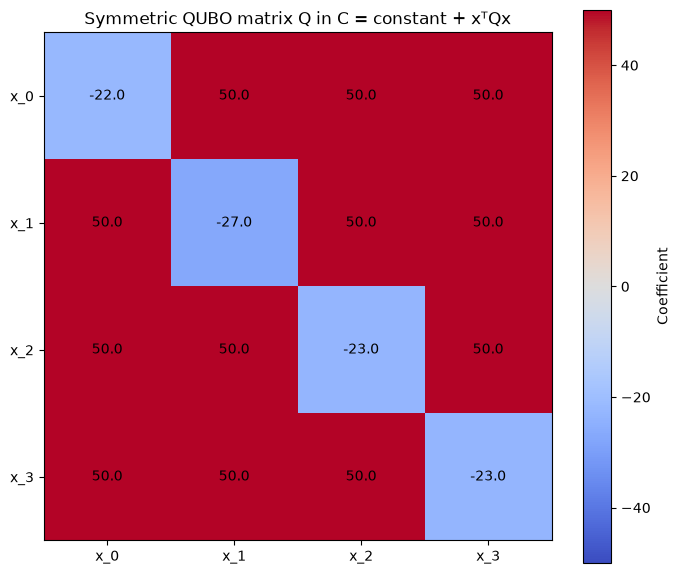

In [56]:
constant, linear, quadratic, qubo_matrix = build_qubo(risk_scores, PENALTY)

print("Constant term:", constant)
display(pd.DataFrame({"variable": variable_map["binary_variable"], "linear_coefficient": linear}))
display(
    pd.DataFrame(
        [
            {"quadratic_term": f"x_{first} x_{second}", "coefficient": coefficient}
            for (first, second), coefficient in quadratic.items()
        ]
    )
)
display(qubo_matrix)

save_qubo_matrix_figure(qubo_matrix, RESULTS_DIR / "qubo_matrix.png")

## 10. Complete brute-force evaluation

Four bits have $2^4=16$ assignments. The transparent solver generates every one, evaluates the risk term and penalty term separately, marks whether exactly one bit is set, and adds them to obtain the QUBO cost. Because this instance is tiny, exhaustive search gives the exact reference answer without an external optimizer.

In [57]:
brute_force_table, best_assignment, classical_optimum = solve_qubo(
    route_names,
    risk_scores,
    PENALTY,
)
display(brute_force_table)
brute_force_table.to_csv(RESULTS_DIR / "brute_force_evaluation.csv", index=False)

best_bitstring = "".join(str(bit) for bit in best_assignment)
print("Assignments evaluated:", len(brute_force_table))
print("Valid assignments:", int(brute_force_table["valid"].sum()))
print("Classical optimum bitstring:", best_bitstring)
print("Classical optimum route:", classical_optimum)
print("Classical optimum QUBO cost:", brute_force_table["qubo_cost"].min())

assert len(brute_force_table) == 16
assert int(brute_force_table["valid"].sum()) == 4
assert best_bitstring == "0100"
assert classical_optimum == "Route B"


,bitstring,x_0,x_1,x_2,x_3,selected_count,valid,risk_term,penalty_term,qubo_cost,selected_routes
0,0000,0,0,0,0,0,False,0.000000,50.000000,50.000000,None
1,0001,0,0,0,1,1,True,27.000000,0.000000,27.000000,Route D
2,0010,0,0,1,0,1,True,27.000000,0.000000,27.000000,Route C
3,0011,0,0,1,1,2,False,54.000000,50.000000,104.000000,"Route C, Route D"
4,0100,0,1,0,0,1,True,23.000000,0.000000,23.000000,Route B
5,0101,0,1,0,1,2,False,50.000000,50.000000,100.000000,"Route B, Route D"
6,0110,0,1,1,0,2,False,50.000000,50.000000,100.000000,"Route B, Route C"
7,0111,0,1,1,1,3,False,77.000000,200.000000,277.000000,"Route B, Route C, Route D"
8,1000,1,0,0,0,1,True,28.000000,0.000000,28.000000,Route A
9,1001,1,0,0,1,2,False,55.000000,50.000000,105.000000,"Route A, Route D"


Assignments evaluated: 16
Valid assignments: 4
Classical optimum bitstring: 0100
Classical optimum route: Route B
Classical optimum QUBO cost: 23.0


## 11. Binary-to-Ising conversion

Pauli-Z has eigenvalue $+1$ on $|0\rangle$ and $-1$ on $|1\rangle$. Therefore the binary variable is replaced manually by

$$x_i=\frac{1-Z_i}{2}.$$

For a linear coefficient $a_i$:

$$a_i x_i=\frac{a_i}{2}-\frac{a_i}{2}Z_i.$$

For a pair coefficient $b_{ij}$:

$$b_{ij}x_i x_j=\frac{b_{ij}}{4}(1-Z_i-Z_j+Z_iZ_j).$$

Collecting all identity pieces gives a constant offset. Collecting single-Z and two-Z pieces gives the cost Hamiltonian. The code below performs only this displayed arithmetic; no QUBO conversion package is used.

In [58]:
cost_hamiltonian, ising_offset, z_coefficients, zz_coefficients = qubo_to_ising(
    constant,
    linear,
    quadratic,
)

print("Identity offset:", ising_offset)
display(
    pd.DataFrame(
        {
            "term": [f"Z_{wire}" for wire in range(4)],
            "coefficient": z_coefficients,
        }
    )
)
display(
    pd.DataFrame(
        [
            {"term": f"Z_{first} Z_{second}", "coefficient": coefficient}
            for (first, second), coefficient in zz_coefficients.items()
        ]
    )
)

Identity offset: 152.5


,term,coefficient
0,Z_0,-64.000000
1,Z_1,-61.500000
2,Z_2,-63.500000
3,Z_3,-63.500000


,term,coefficient
0,Z_0 Z_1,25.000000
1,Z_0 Z_2,25.000000
2,Z_0 Z_3,25.000000
3,Z_1 Z_2,25.000000
4,Z_1 Z_3,25.000000
5,Z_2 Z_3,25.000000


## 12. Cost Hamiltonian

The non-identity part is

$$H_C=\sum_i h_i Z_i+\sum_{i<j}J_{ij}Z_iZ_j.$$

`qml.PauliZ(i)` supplies a one-wire Z observable. `qml.PauliZ(i) @ qml.PauliZ(j)` supplies the product observable for a quadratic interaction. `qml.Hamiltonian` stores their weighted sum.

The identity offset is omitted from $H_C$ because adding the same constant to every state cannot change the minimizing bitstring or parameter gradient. It is not discarded: for every basis state,

$$C(x)=\langle x|H_C|x\rangle+\mathrm{offset}.$$

The table below checks that equality against the actual PennyLane Hamiltonian matrix for all 16 bitstrings.

In [59]:
print(cost_hamiltonian)
hamiltonian_matrix = np.asarray(qml.matrix(cost_hamiltonian, wire_order=range(4)))
energy_check_rows = []

for assignment in generate_binary_assignments(4):
    bitstring = "".join(str(bit) for bit in assignment)
    basis_index = int(bitstring, 2)
    hamiltonian_energy = float(np.real(hamiltonian_matrix[basis_index, basis_index]))
    qubo_cost = evaluate_qubo(assignment, constant, linear, quadratic)
    reconstructed_cost = hamiltonian_energy + ising_offset
    energy_check_rows.append(
        {
            "bitstring": bitstring,
            "QUBO_cost": qubo_cost,
            "Hamiltonian_plus_offset": reconstructed_cost,
            "absolute_difference": abs(qubo_cost - reconstructed_cost),
        }
    )

energy_check = pd.DataFrame(energy_check_rows)
display(energy_check)
print("Maximum energy difference:", energy_check["absolute_difference"].max())
assert energy_check["absolute_difference"].max() < 1e-9

-64.0 * Z(0) + -61.5 * Z(1) + -63.5 * Z(2) + -63.5 * Z(3) + 25.0 * (Z(0) @ Z(1)) + 25.0 * (Z(0) @ Z(2)) + 25.0 * (Z(0) @ Z(3)) + 25.0 * (Z(1) @ Z(2)) + 25.0 * (Z(1) @ Z(3)) + 25.0 * (Z(2) @ Z(3))


,bitstring,QUBO_cost,Hamiltonian_plus_offset,absolute_difference
0,0000,50.000000,50.000000,0.000000
1,0001,27.000000,27.000000,0.000000
2,0010,27.000000,27.000000,0.000000
3,0011,104.000000,104.000000,0.000000
4,0100,23.000000,23.000000,0.000000
5,0101,100.000000,100.000000,0.000000
6,0110,100.000000,100.000000,0.000000
7,0111,277.000000,277.000000,0.000000
8,1000,28.000000,28.000000,0.000000
9,1001,105.000000,105.000000,0.000000


Maximum energy difference: 0.0


## 13. QAOA circuit

The circuit uses `qml.device("default.qubit", wires=4)`. It has four kinds of quantum operation:

1. `qml.Hadamard` puts each zero-initialized wire into an equal superposition, giving initial support to all 16 bitstrings.
2. `qml.qaoa.cost_layer(gamma, H_C)` applies $e^{-i\gamma H_C}$, giving cost-dependent phases through the Z and ZZ terms.
3. The mixer Hamiltonian $H_M=X_0+X_1+X_2+X_3$ uses `qml.PauliX`, whose action flips zero and one. `qml.qaoa.mixer_layer(beta, H_M)` applies $e^{-i\beta H_M}$ so interference can move probability between bitstrings.
4. The analytic training QNode returns `qml.expval(H_C)`, the probability-weighted average energy. The separate finite-shot QNode later returns `qml.sample` in explicit wire order `[0, 1, 2, 3]`.

PennyLane draws each layer as `ApproxTimeEvolution`. One product-formula step is exact here because all Z/ZZ cost terms commute with each other, and all single-wire X mixer terms commute with each other.

Gamma controls the cost phase; beta controls mixing. QAOA depth $p$ is the number of cost/mixer pairs. The standard X mixer can enter invalid states, so the exactly-one penalty remains necessary.

0: ──H ···
1: ──H ···
2: ──H ···
3: ──H ···

0: ··· ─╭ApproxTimeEvolution(-64.00,-61.50,-63.50,-63.50,25.00,25.00,25.00,25.00,25.00,25.00,0.02) ···
1: ··· ─├ApproxTimeEvolution(-64.00,-61.50,-63.50,-63.50,25.00,25.00,25.00,25.00,25.00,25.00,0.02) ···
2: ··· ─├ApproxTimeEvolution(-64.00,-61.50,-63.50,-63.50,25.00,25.00,25.00,25.00,25.00,25.00,0.02) ···
3: ··· ─╰ApproxTimeEvolution(-64.00,-61.50,-63.50,-63.50,25.00,25.00,25.00,25.00,25.00,25.00,0.02) ···

0: ··· ─╭ApproxTimeEvolution(1.00,1.00,1.00,1.00,-0.20)─┤ ╭<𝓗>
1: ··· ─├ApproxTimeEvolution(1.00,1.00,1.00,1.00,-0.20)─┤ ├<𝓗>
2: ··· ─├ApproxTimeEvolution(1.00,1.00,1.00,1.00,-0.20)─┤ ├<𝓗>
3: ··· ─╰ApproxTimeEvolution(1.00,1.00,1.00,1.00,-0.20)─┤ ╰<𝓗>


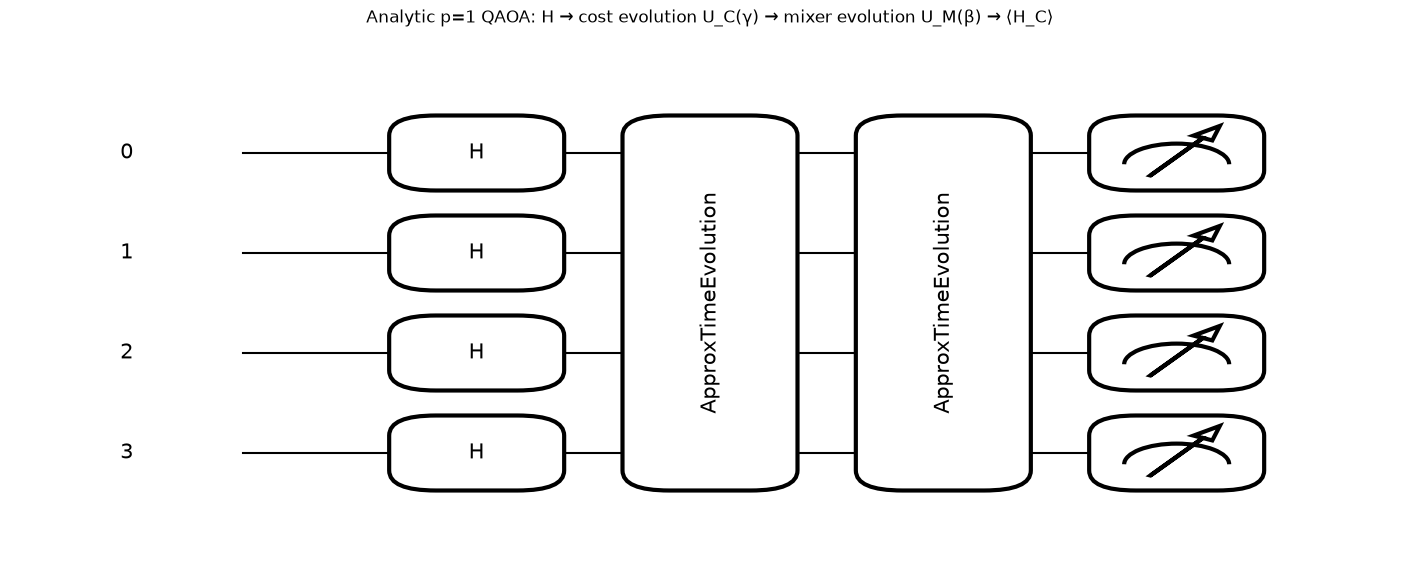

In [60]:
mixer_hamiltonian = create_mixer_hamiltonian(number_of_qubits=4)
preview_training_qnode = create_training_qnode(
    cost_hamiltonian,
    mixer_hamiltonian,
    depth=1,
)
preview_gammas = pnp.array([0.02], requires_grad=True)
preview_betas = pnp.array([-0.20], requires_grad=True)

print(qml.draw(preview_training_qnode)(preview_gammas, preview_betas))
save_qaoa_circuit_figure(
    preview_training_qnode,
    preview_gammas,
    preview_betas,
    RESULTS_DIR / "qaoa_circuit.png",
)

## 14. Classical parameter optimization

QAOA is hybrid. The quantum circuit supplies the analytic expectation $\langle H_C\rangle$; PennyLane's gradient-based Adam optimizer runs classically and updates gamma and beta to reduce it.

Both experiments use 100 iterations, step size 0.02, initial gamma 0.02 in every layer, and initial beta -0.20 in every layer. These fixed choices make the run understandable and reproducible. A lower expectation is useful, but it does not prove that the most sampled valid bitstring must be the exact optimum.

,depth_p,initial_expectation,final_expectation,optimized_gammas,optimized_betas
0,1,23.294409,-103.839962,[0.00667864],[-0.46757507]
1,2,72.271174,-124.232245,"[0.00670047, 0.09419048]","[-0.43436998, -0.19881004]"


,depth_p,iteration,cost_expectation
0,1,0,23.294409
1,1,1,-0.000000
2,1,2,-31.209445
3,1,3,-7.936667
4,1,4,-36.978666
...,...,...,...
197,2,96,-124.208495
198,2,97,-124.228731
199,2,98,-124.248518
200,2,99,-124.219848


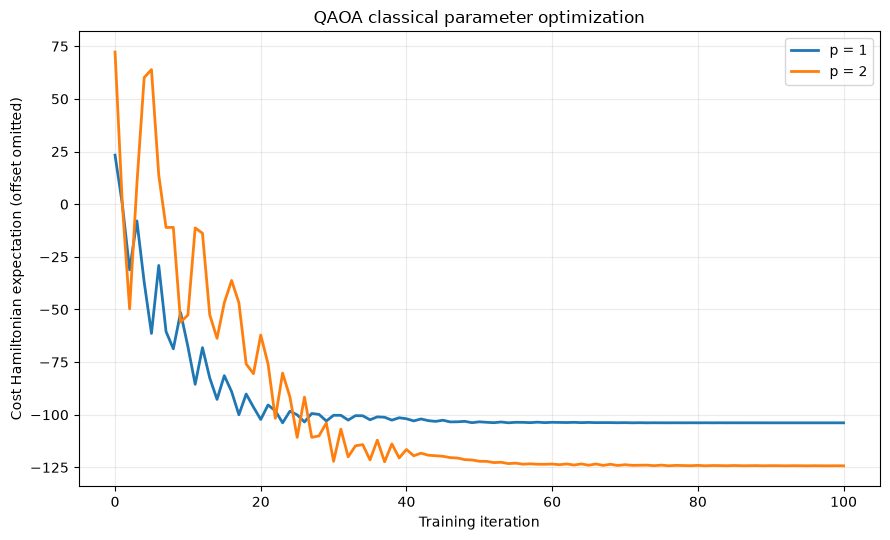

In [61]:
training_qnodes = {}
optimized_parameters = {}
training_histories = {}
parameter_rows = []

for depth in DEPTHS:
    training_qnode = create_training_qnode(
        cost_hamiltonian,
        mixer_hamiltonian,
        depth,
    )
    gammas, betas, history = optimize_qaoa(
        training_qnode,
        depth,
        iterations=TRAINING_ITERATIONS,
        step_size=STEP_SIZE,
        initial_gammas=[0.02] * depth,
        initial_betas=[-0.20] * depth,
    )
    training_qnodes[depth] = training_qnode
    optimized_parameters[depth] = (gammas, betas)
    training_histories[depth] = history
    parameter_rows.append(
        {
            "depth_p": depth,
            "initial_expectation": history.iloc[0]["cost_expectation"],
            "final_expectation": history.iloc[-1]["cost_expectation"],
            "optimized_gammas": [round(float(value), 8) for value in gammas],
            "optimized_betas": [round(float(value), 8) for value in betas],
        }
    )

parameter_results = pd.DataFrame(parameter_rows)
display(parameter_results)

history_display = pd.concat(
    [history.assign(depth_p=depth) for depth, history in training_histories.items()],
    ignore_index=True,
)[["depth_p", "iteration", "cost_expectation"]]
display(history_display)
parameter_results.to_csv(RESULTS_DIR / "optimized_parameters.csv", index=False)
history_display.to_csv(RESULTS_DIR / "training_history.csv", index=False)

save_training_history_figure(
    training_histories,
    RESULTS_DIR / "training_history.png",
)

## 15. Measurement results

Training is analytic, but final reporting uses a separate finite-shot QNode. Each depth is sampled 4,000 times with seed 2026. A returned row `[b_0,b_1,b_2,b_3]` is displayed directly as `b_0b_1b_2b_3`, matching wires and variables `x_0x_1x_2x_3`; bits are never reversed.

The valid-solution probability is the fraction of samples containing exactly one `1`. The optimal-route probability is the fraction equal to `0100`, the classically verified Route B state. The most frequent valid route is calculated from measured one-hot counts and is not assumed to be optimal.

,bitstring,p=1 count,p=2 count,valid,decoded_valid_route
0,0000,778,6,False,Invalid
1,0001,656,952,True,Route D
2,0010,634,1018,True,Route C
3,0011,86,0,False,Invalid
4,0100,668,1036,True,Route B
5,0101,101,6,False,Invalid
6,0110,100,5,False,Invalid
7,0111,25,0,False,Invalid
8,1000,587,956,True,Route A
9,1001,95,1,False,Invalid


,depth_p,shots,valid_solution_probability,optimal_route_probability,most_frequent_valid_route
0,1,4000,0.636250,0.167000,Route B
1,2,4000,0.990500,0.259000,Route B


p=1 valid route counts: {'Route A': 587, 'Route B': 668, 'Route C': 634, 'Route D': 656}
p=2 valid route counts: {'Route A': 956, 'Route B': 1036, 'Route C': 1018, 'Route D': 952}


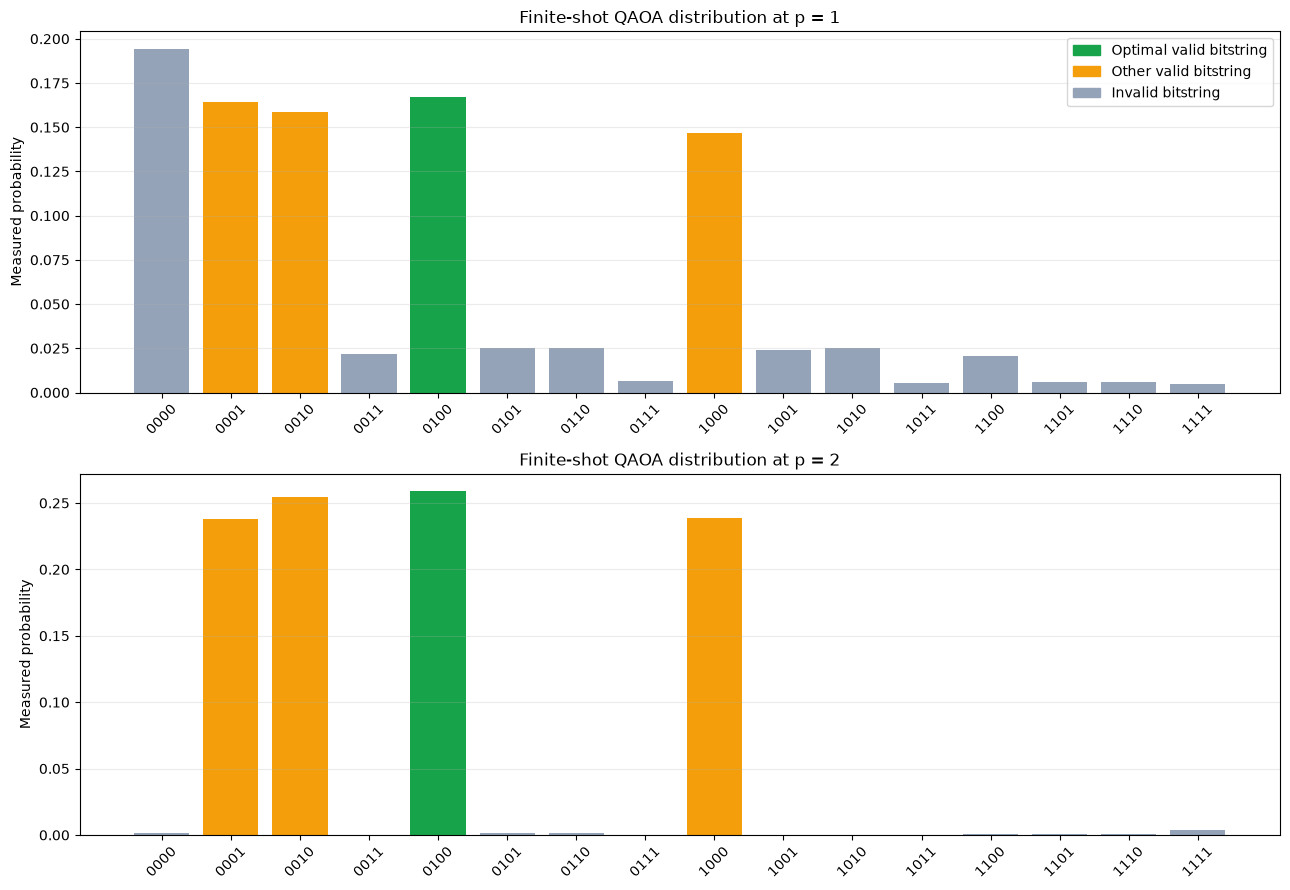

In [62]:
sample_summaries = {}
measurement_metric_rows = []

for depth in DEPTHS:
    gammas, betas = optimized_parameters[depth]
    sampling_qnode = create_sampling_qnode(
        cost_hamiltonian,
        mixer_hamiltonian,
        depth,
        shots=FINAL_SHOTS,
        seed=RANDOM_SEED,
    )
    samples = np.asarray(sampling_qnode(gammas, betas), dtype=int)
    summary = summarize_samples(samples, route_names, classical_optimum)
    sample_summaries[depth] = summary
    measurement_metric_rows.append(
        {
            "depth_p": depth,
            "shots": FINAL_SHOTS,
            "valid_solution_probability": summary["valid_solution_probability"],
            "optimal_route_probability": summary["optimal_route_probability"],
            "most_frequent_valid_route": summary["most_frequent_valid_route"],
        }
    )

all_bitstrings = list(sample_summaries[1]["counts"].keys())
count_table = pd.DataFrame({"bitstring": all_bitstrings})
for depth in DEPTHS:
    count_table[f"p={depth} count"] = [
        sample_summaries[depth]["counts"][bitstring] for bitstring in all_bitstrings
    ]
count_table["valid"] = count_table["bitstring"].str.count("1") == 1
bitstring_to_route = {"1000": "Route A", "0100": "Route B", "0010": "Route C", "0001": "Route D"}
count_table["decoded_valid_route"] = count_table["bitstring"].map(bitstring_to_route).fillna("Invalid")

display(count_table)
measurement_metrics = pd.DataFrame(measurement_metric_rows)
display(measurement_metrics)
count_table.to_csv(RESULTS_DIR / "measurement_counts.csv", index=False)
measurement_metrics.to_csv(RESULTS_DIR / "qaoa_metrics.csv", index=False)

for depth in DEPTHS:
    print(f"p={depth} valid route counts:", sample_summaries[depth]["valid_route_counts"])

save_measurement_probabilities_figure(
    sample_summaries,
    optimal_bitstring="0100",
    output_path=RESULTS_DIR / "measurement_probabilities.png",
)

## 16. Classical versus QAOA comparison

Exhaustive search gives a deterministic proof that Route B and `0100` minimize this QUBO. QAOA instead supplies a distribution: its most frequent valid route and probabilities are empirical finite-shot summaries.

It is appropriate to compare them, but not to call the simulator faster, superior, or guaranteed. If a QAOA run ranks a different valid route first, that can result from shallow depth, a local parameter optimum, the non-constraint-preserving X mixer, small route-energy gaps, or finite-shot randomness. Such a result would be reported rather than overwritten.

In [63]:
comparison_rows = [
    {
        "method": "Expected-time baseline",
        "reported_route": expected_time_choice,
        "valid_solution_probability": 1.0,
        "Route_B_probability": 0.0,
        "interpretation": "Deterministic minimum expected time",
    },
    {
        "method": "Classical risk-aware exhaustive QUBO",
        "reported_route": classical_optimum,
        "valid_solution_probability": 1.0,
        "Route_B_probability": 1.0,
        "interpretation": "Exact optimum over all 16 states",
    },
]

for depth in DEPTHS:
    summary = sample_summaries[depth]
    comparison_rows.append(
        {
            "method": f"QAOA p={depth}, {FINAL_SHOTS} shots",
            "reported_route": summary["most_frequent_valid_route"],
            "valid_solution_probability": summary["valid_solution_probability"],
            "Route_B_probability": summary["optimal_route_probability"],
            "interpretation": "Most frequent measured valid route",
        }
    )

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table)

for depth in DEPTHS:
    summary = sample_summaries[depth]
    if summary["most_frequent_valid_route"] != classical_optimum:
        print(
            f"At p={depth}, QAOA did not rank Route B first. "
            "This is a finite-depth, finite-optimization, finite-shot outcome rather than a contradiction of the exact solver."
        )

,method,reported_route,valid_solution_probability,Route_B_probability,interpretation
0,Expected-time baseline,Route A,1.000000,0.000000,Deterministic minimum expected time
1,Classical risk-aware exhaustive QUBO,Route B,1.000000,1.000000,Exact optimum over all 16 states
2,"QAOA p=1, 4000 shots",Route B,0.636250,0.167000,Most frequent measured valid route
3,"QAOA p=2, 4000 shots",Route B,0.990500,0.259000,Most frequent measured valid route


## 17. Limitations

- The network, expected times, and uncertainty values are synthetic.
- The uncertainty inputs are manually simulated, not calibrated prediction intervals.
- There is no traffic prediction, time dependence, rerouting, or multiple-vehicle coordination.
- Candidate paths are supplied in advance rather than discovered in a realistic road network.
- The standard Pauli-X mixer visits invalid states.
- Only depths 1 and 2 and one fixed initialization are studied.
- `default.qubit` is a noiseless simulator; finite shots add sampling variability but not hardware noise.
- Four qubits are too small for a scaling or quantum-advantage claim.
- The risk score is a transparent preference formula, not a validated medical or operational utility.

## 18. Next research milestone

The next milestone will replace manual uncertainty with calibrated machine-learning prediction intervals from an appropriate offline traffic dataset. It must first define coverage and interval-width metrics, compare against simple prediction baselines, and verify calibration before feeding intervals into the route score.

Dynamic rerouting, multiple emergency vehicles, realistic maps, noise studies, and hardware remain later milestones. They are intentionally not implemented here.

In [64]:
expected_figure_names = [
    "road_network.png",
    "route_comparison.png",
    "qubo_matrix.png",
    "qaoa_circuit.png",
    "training_history.png",
    "measurement_probabilities.png",
]
figure_check = pd.DataFrame(
    [
        {
            "figure": figure_name,
            "exists": (RESULTS_DIR / figure_name).exists(),
            "bytes": (RESULTS_DIR / figure_name).stat().st_size if (RESULTS_DIR / figure_name).exists() else 0,
        }
        for figure_name in expected_figure_names
    ]
)
display(figure_check)
assert figure_check["exists"].all()
assert (figure_check["bytes"] > 0).all()
print("Milestone complete. Advanced features were not started.")

expected_table_names = [
    "brute_force_evaluation.csv",
    "optimized_parameters.csv",
    "training_history.csv",
    "measurement_counts.csv",
    "qaoa_metrics.csv",
]
for table_name in expected_table_names:
    table_path = RESULTS_DIR / table_name
    assert table_path.exists() and table_path.stat().st_size > 0
print("Complete numeric result tables saved:", ", ".join(expected_table_names))

,figure,exists,bytes
0,road_network.png,True,313391
1,route_comparison.png,True,49484
2,qubo_matrix.png,True,52554
3,qaoa_circuit.png,True,83097
4,training_history.png,True,94193
5,measurement_probabilities.png,True,122661


Milestone complete. Advanced features were not started.
Complete numeric result tables saved: brute_force_evaluation.csv, optimized_parameters.csv, training_history.csv, measurement_counts.csv, qaoa_metrics.csv
